# 02 · Exploração dos dados (EDA)

Quatro perguntas:

1. Como se distribuem os preços?
2. A área explica o preço?
3. A localização importa?
4. Que variáveis estão mais ligadas ao preço?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DADOS = Path("..") / "data"
FIGURAS = Path("..") / "figuras"        # alguns gráficos ficam gravados aqui, para o README
FIGURAS.mkdir(exist_ok=True)
AZUL, LARANJA = "#2a78d6", "#eb6834"

df = pd.read_csv(DADOS / "processed" / "dados_limpos.csv")
df["preco_m2"] = df["preco"] / df["area_m2"]   # só para explorar (não entra no modelo)
df[["preco", "area_m2", "preco_m2", "quartos"]].describe().round(0)

,preco,area_m2,preco_m2,quartos
count,1623.0,1623.0,1623.0,1623.0
mean,979538.0,135.0,7202.0,3.0
std,790785.0,79.0,2429.0,1.0
min,139000.0,26.0,2135.0,0.0
25%,527500.0,82.0,5564.0,2.0
50%,735000.0,116.0,6805.0,2.0
75%,1152500.0,165.0,8333.0,3.0
max,10000000.0,600.0,25750.0,8.0


## 1. Como se distribuem os preços?

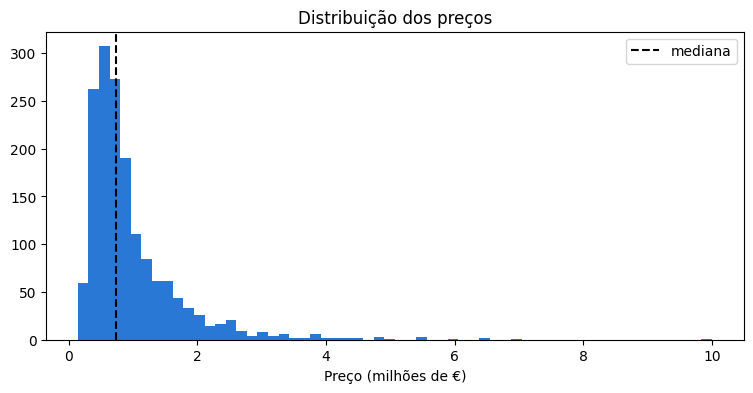

Mediana: 735 mil € | Média: 980 mil €
Acima de 2,5 milhões: 4.3% dos anúncios


In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df["preco"] / 1e6, bins=60, color=AZUL)
ax.axvline(df["preco"].median() / 1e6, color="black", linestyle="--", label="mediana")
ax.set_title("Distribuição dos preços")
ax.set_xlabel("Preço (milhões de €)")
ax.legend()
plt.show()

print(f"Mediana: {df['preco'].median() / 1000:.0f} mil € | Média: {df['preco'].mean() / 1000:.0f} mil €")
print(f"Acima de 2,5 milhões: {(df['preco'] > 2_500_000).mean():.1%} dos anúncios")

O que vemos: metade das casas custa entre cerca de 530 mil € e 1,15 milhões, mas há uma cauda longa de casas muito caras, que puxam a média (980 mil €) para cima da mediana (735 mil €). No notebook 03 tiramos as casas de luxo e usamos o logaritmo do preço.

## 2. A área explica o preço?

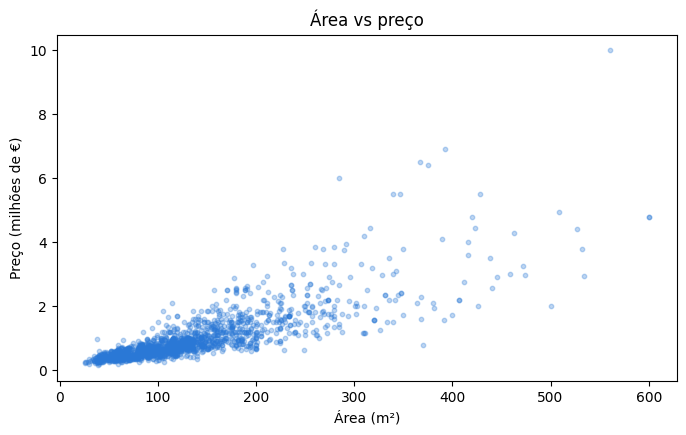

Correlação entre área e preço: 0.81


In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(df["area_m2"], df["preco"] / 1e6, s=10, alpha=0.3, color=AZUL)
ax.set_title("Área vs preço")
ax.set_xlabel("Área (m²)")
ax.set_ylabel("Preço (milhões de €)")
plt.show()

print(f"Correlação entre área e preço: {df['area_m2'].corr(df['preco']):.2f}")

O que vemos: casas maiores custam mais (correlação de 0,81). Mas, para a mesma área, o preço varia muito, e mais nas casas grandes (os pontos "abrem em leque").

## 3. A localização importa?

Comparamos o preço por m² mediano de cada freguesia.

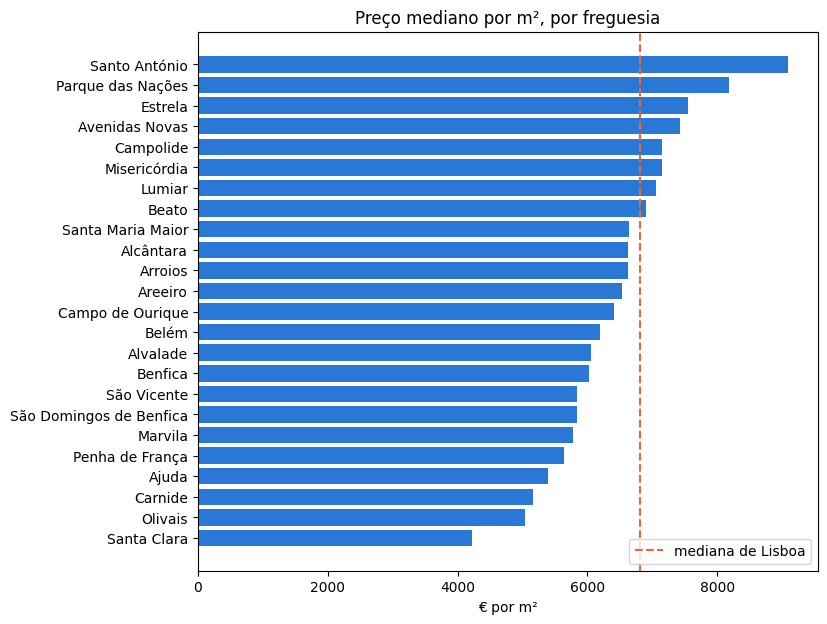

In [4]:
por_freguesia = df.groupby("freguesia")["preco_m2"].median().sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(por_freguesia.index, por_freguesia.values, color=AZUL)
ax.axvline(df["preco_m2"].median(), color=LARANJA, linestyle="--", label="mediana de Lisboa")
ax.set_title("Preço mediano por m², por freguesia")
ax.set_xlabel("€ por m²")
ax.legend(loc="lower right")
plt.savefig(FIGURAS / "preco_m2_freguesia.png", dpi=120, bbox_inches="tight")
plt.show()

O que vemos: o m² em Santo António (cerca de 9 100 €) custa mais do dobro do de Santa Clara (cerca de 4 200 €). A localização pesa muito.

Com as coordenadas de cada casa podemos desenhar um mapa. A cidade é dividida em pequenos hexágonos, e cada um é pintado com o preço mediano por m² das casas lá dentro (só aparecem hexágonos com pelo menos 3 casas).

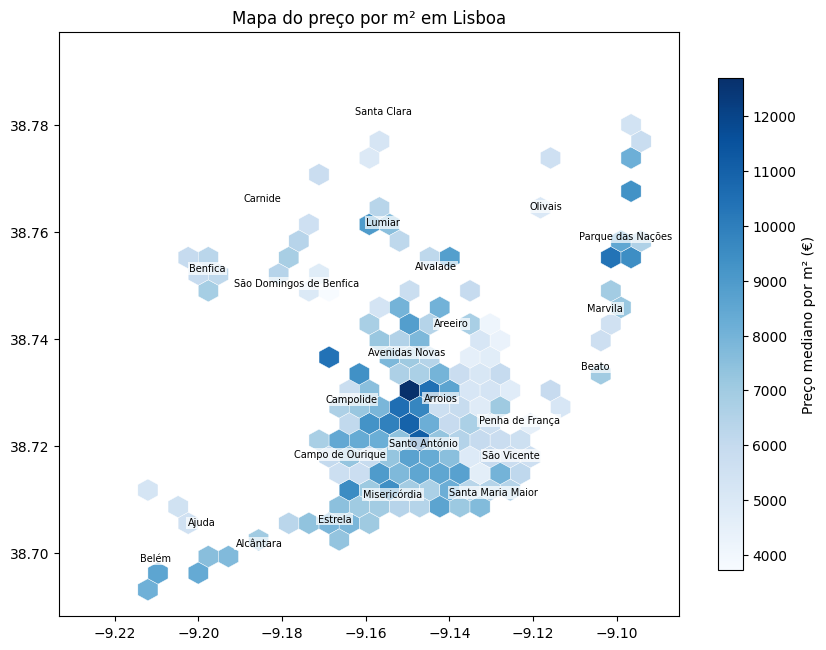

In [5]:
fig, ax = plt.subplots(figsize=(10, 8))
mapa = ax.hexbin(df["longitude"], df["latitude"], C=df["preco_m2"], reduce_C_function=np.median,
                 gridsize=28, mincnt=3, cmap="Blues", edgecolors="white", linewidths=0.3)
fig.colorbar(mapa, ax=ax, label="Preço mediano por m² (€)", shrink=0.8)

# Nome de cada freguesia, no ponto central das suas casas
centros = df.groupby("freguesia")[["longitude", "latitude"]].median()
# Alguns nomes ficavam uns em cima dos outros: afastamo-los um pouco (longitude, latitude)
centros.loc["Arroios"] += [-0.005, 0.002]
centros.loc["Penha de França"] += [0.006, -0.001]
centros.loc["Misericórdia"] += [-0.007, 0]
centros.loc["Santa Maria Maior"] += [0.006, 0]

for nome, centro in centros.iterrows():   # uma volta por freguesia
    ax.text(centro["longitude"], centro["latitude"], nome, fontsize=7, ha="center", va="center",
            bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none", "pad": 1})

ax.set_aspect(1.28)   # para o mapa não ficar deformado
ax.set_title("Mapa do preço por m² em Lisboa")
plt.savefig(FIGURAS / "mapa_preco_m2.png", dpi=120, bbox_inches="tight")
plt.show()

O que vemos: os preços mais altos estão no centro (Santo António, Avenidas Novas, Estrela) e descem quando nos afastamos. Há exceções, como o Parque das Nações, caro apesar de ficar longe. Além da freguesia, vamos dar ao modelo as coordenadas e a distância ao centro (notebook 03).

## 4. Que variáveis estão mais ligadas ao preço?

A correlação vai de -1 a 1: perto de 1, as duas variáveis sobem juntas; perto de -1, quando uma sobe a outra desce; perto de 0, não há relação em linha reta.

A matriz de correlação mostra a correlação de todas as variáveis, duas a duas. A primeira linha é a correlação de cada uma com o preço.

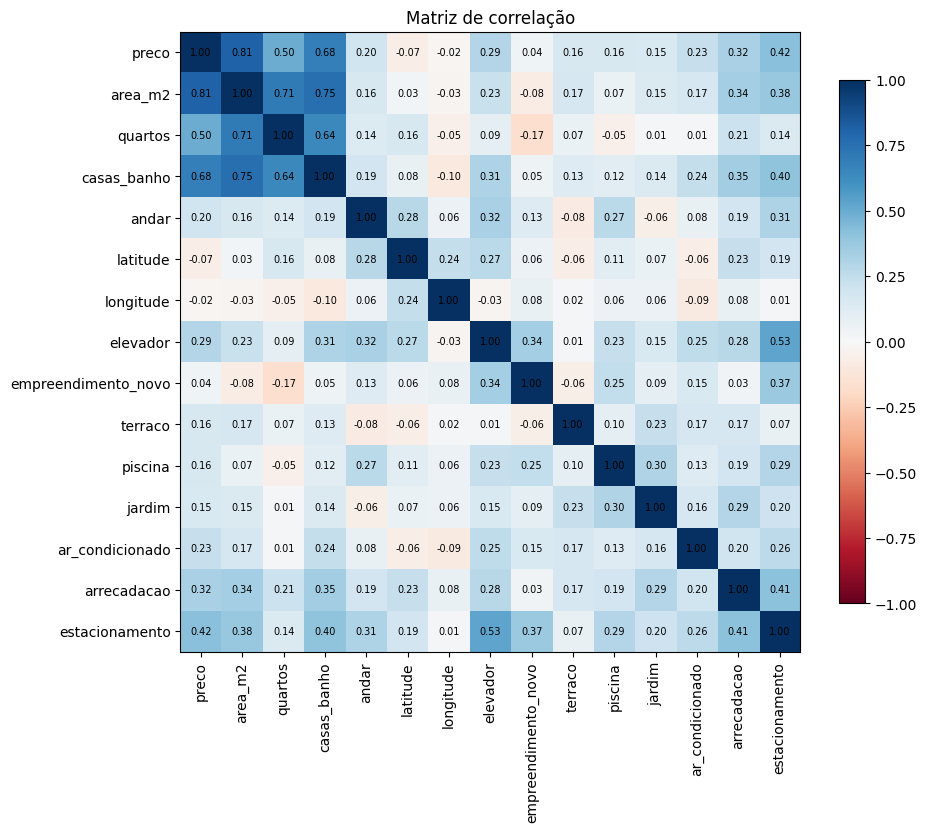

In [6]:
colunas = ["preco", "area_m2", "quartos", "casas_banho", "andar", "latitude", "longitude",
           "elevador", "empreendimento_novo", "terraco", "piscina", "jardim",
           "ar_condicionado", "arrecadacao", "estacionamento"]
correlacao = df[colunas].corr()   # correlação entre todos os pares de colunas

fig, ax = plt.subplots(figsize=(10, 8.5))
imagem = ax.imshow(correlacao, cmap="RdBu", vmin=-1, vmax=1)   # azul = positiva, vermelho = negativa
fig.colorbar(imagem, ax=ax, shrink=0.8)
ax.set_xticks(range(len(colunas)), colunas, rotation=90)
ax.set_yticks(range(len(colunas)), colunas)
for i in range(len(colunas)):          # escrever o valor em cada quadrado
    for j in range(len(colunas)):
        ax.text(j, i, f"{correlacao.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Matriz de correlação")
plt.show()

O que vemos:

- A área (0,81) e as casas de banho (0,68) são as variáveis mais ligadas ao preço; entre os extras, o estacionamento, a arrecadação e o elevador.
- A área, os quartos e as casas de banho estão muito ligados entre si (0,64 a 0,75): casas grandes têm mais de tudo. Dizem em parte a mesma coisa.
- A latitude e a longitude quase não têm correlação com o preço. Não quer dizer que a localização não importe (o mapa mostra que importa): os preços são altos no centro e descem para todos os lados, o que não é uma linha reta.

## Conclusões para o notebook 03

| O que vimos | O que fazemos |
|---|---|
| Preços com cauda longa e algumas casas de luxo | Tirar as casas acima de 2,5 milhões; usar o logaritmo do preço |
| A área explica muito, mas em leque | Usar o logaritmo da área |
| O preço é mais alto no centro | Criar a distância ao centro |